# Model Performance

This notebook aims to evaluate calibration performances across demographics.

First, we load the predictions obtained in the previous notebook

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import brier_score_loss
from sklearn.metrics import roc_auc_score
from sklearn.calibration import calibration_curve

# load global predictions
global_predictions = pd.read_csv("../data/processed/predictions/global_predictions.csv")

demographic_datasets = {
    "sex": ["female", "male"],
    "age": ["younger_adult", "middle_age", "older"],
    "income": ["lower_income", "middle_income", "higher_income"],
    "education": ["below_high_school", "high_school", "some_college_or_higher"]
}

# load demographic predictions
demographic_predictions = {}

for category, groups in demographic_datasets.items():
    demographic_predictions[category] = {}

    for group in groups:
        demographic_predictions[category][group] = pd.read_csv(
            f"../data/processed/predictions/{category}_{group}_predictions.csv"
        )

# load global models with demograpic calibration
global_group_predictions = {}

for category, groups in demographic_datasets.items():
    global_group_predictions[category] = {}

    for group in groups:
        global_group_predictions[category][group] = pd.read_csv(
            f"../data/processed/predictions/{category}_{group}_global_calibrated_predictions.csv"
        )

Here, we calculate brier scores, which measure the accuracy of probability prediction by using the mean squared difference between predicted probabilities and real outcomes. The scores range from 0 to 1, with lower scores indicating better accuracy. The brier scores will be calculated for global models, demographic models, and demographic calibrated models.

We also calculate ROC-AUC scores, which measure how well a model can distinguish those with and without diabetes. A value close to 1 is desired, and a value 0f 0.5 is equivalent to guessing.

In [2]:
global_brier_scores = {}
global_roc_auc = {}

# preiction columns
columns = [
    "log_reg_uncalibrated",
    "log_reg_sigmoid",
    "log_reg_isotonic",
    "gb_uncalibrated",
    "gb_sigmoid",
    "gb_isotonic"
]

# calculate global brier scores and roc-auc
for name in columns:
    global_brier_scores[name] = brier_score_loss(
        global_predictions["y_true"],
        global_predictions[name]
    )
    global_roc_auc[name] = roc_auc_score(
        global_predictions["y_true"],
        global_predictions[name]
    )

# turn to df
global_brier_scores = pd.DataFrame(
    global_brier_scores.items(),
    columns=["Model", "Brier Score"]
)

global_roc_auc = pd.DataFrame(
    global_roc_auc.items(),
    columns=["Model", "ROC-AUC"]
)

In [3]:
demographic_brier_scores = []
demographic_roc_auc = []

# calculate demographic brier scores and roc-auc
for category, groups in demographic_predictions.items():
    for group, predictions in groups.items():
        # test labels for current group
        y_true = predictions["y_true"]
        
        # for all predicted probabilities, get brier score and roc-auc except for actual label
        for name, y_pred in predictions.items(): 
            if name != "y_true":
                demographic_brier_scores.append({
                    "Category": category,
                    "Group": group,
                    "Model": name,
                    "Brier Score": brier_score_loss(y_true, y_pred)
                })
                demographic_roc_auc.append({
                    "Category": category,
                    "Group": group,
                    "Model": name,
                    "ROC-AUC": roc_auc_score(y_true, y_pred)
                })

# convert to df
demographic_brier_scores = pd.DataFrame(demographic_brier_scores)
demographic_roc_auc = pd.DataFrame(demographic_roc_auc)

In [4]:
global_group_brier_scores = []
global_group_roc_auc = []

# calculate brier scores and roc-auc for demographics using models with demgraphic calibration
for category, groups in global_group_predictions.items():
    for group, predictions in groups.items():
        # test labels for current group
        y_true = predictions["y_true"]
        
        # for all predicted probabilities, get brier score and roc-auc except for actual label
        for name, y_pred in predictions.items(): 
            if name != "y_true":
                global_group_brier_scores.append({
                    "Category": category,
                    "Group": group,
                    "Model": name,
                    "Brier Score": brier_score_loss(y_true, y_pred)
                })
                global_group_roc_auc.append({
                    "Category": category,
                    "Group": group,
                    "Model": name,
                    "ROC-AUC": roc_auc_score(y_true, y_pred)
                })

global_group_brier_scores = pd.DataFrame(global_group_brier_scores)
global_group_roc_auc = pd.DataFrame(global_group_roc_auc)

In [5]:
# merge the brier and roc-auc dataframes
global_results = global_brier_scores.merge(
    global_roc_auc,
    on="Model"
)

demographic_results = demographic_brier_scores.merge(
    demographic_roc_auc,
    on=["Category", "Group", "Model"]
)

global_group_results = global_group_brier_scores.merge(
    global_group_roc_auc,
    on=["Category", "Group", "Model"]
)

# save to csv
global_results.to_csv("../data/processed/predictions/global_evaluation.csv", index=False)
demographic_results.to_csv("../data/processed/predictions/demographic_evaluation.csv", index=False)
global_group_results.to_csv("../data/processed/predictions/global_group_evaluation.csv", index=False)

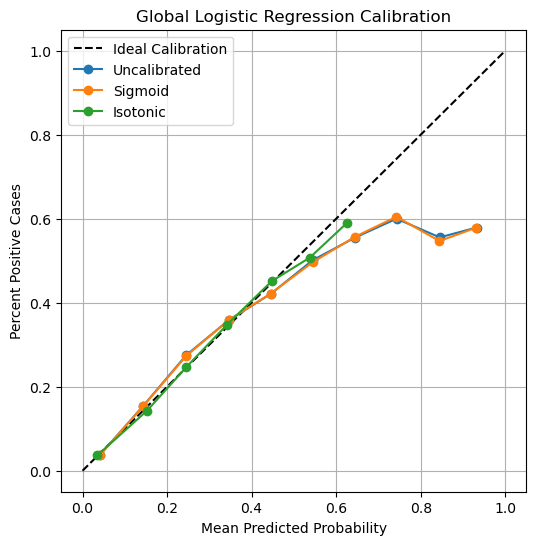

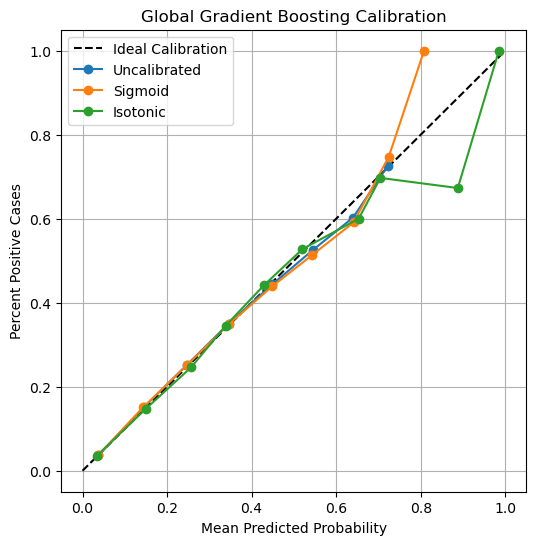

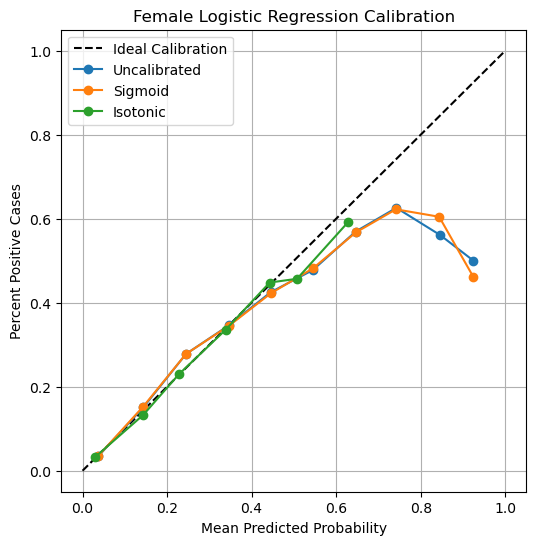

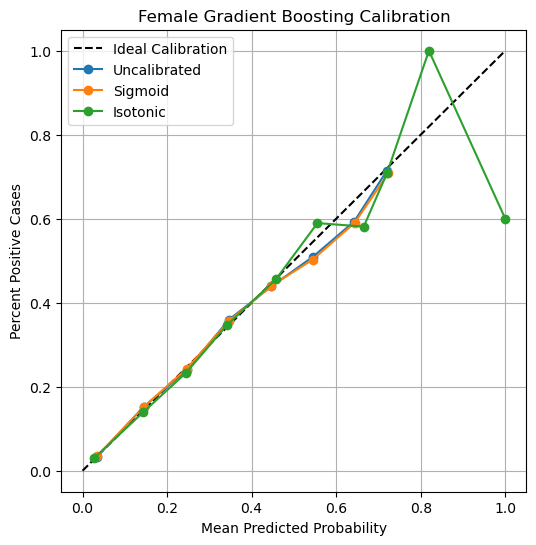

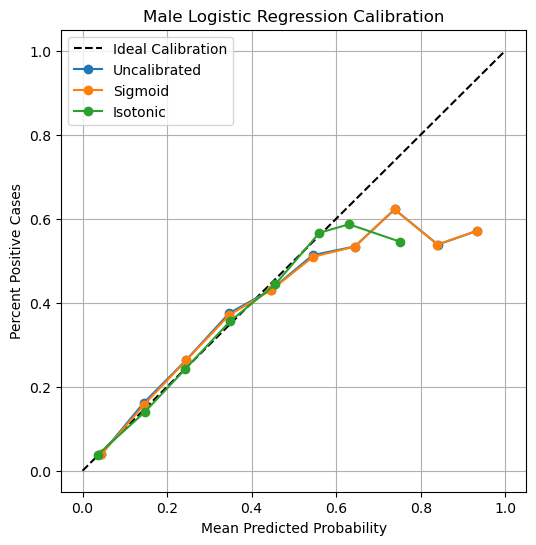

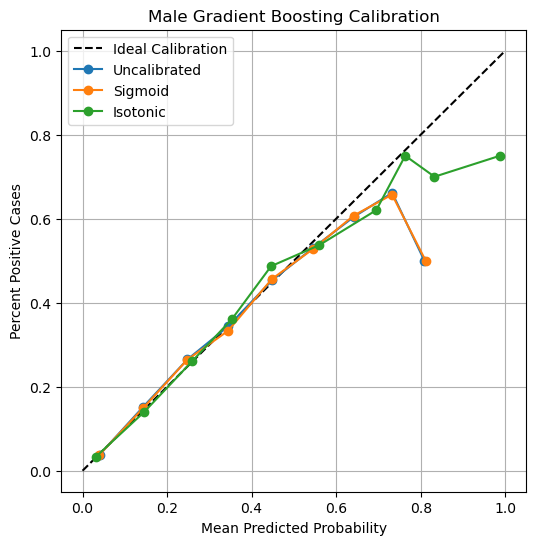

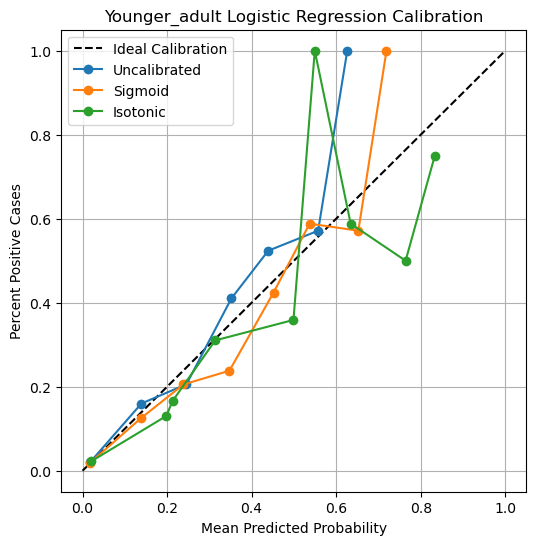

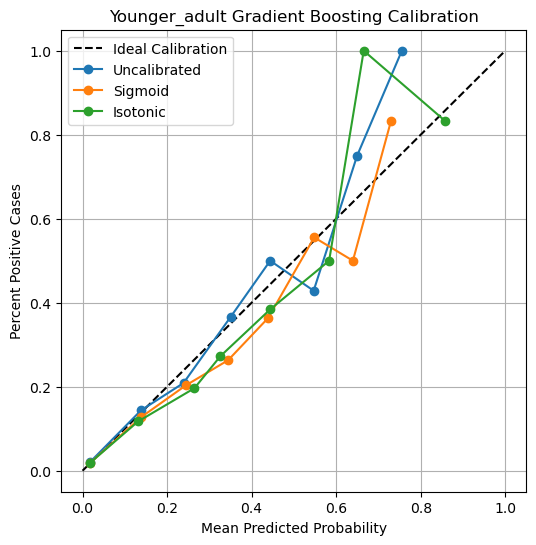

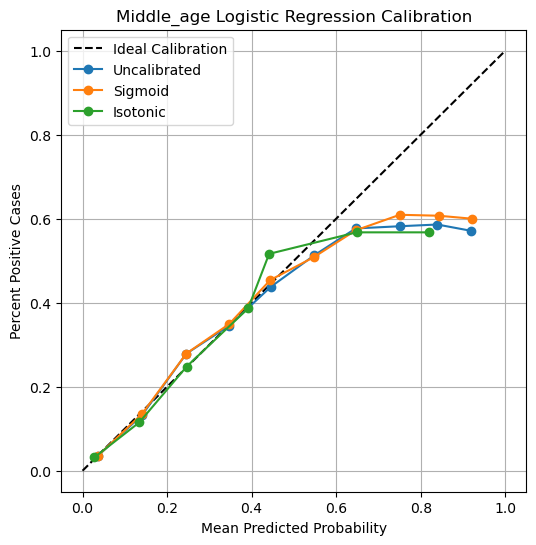

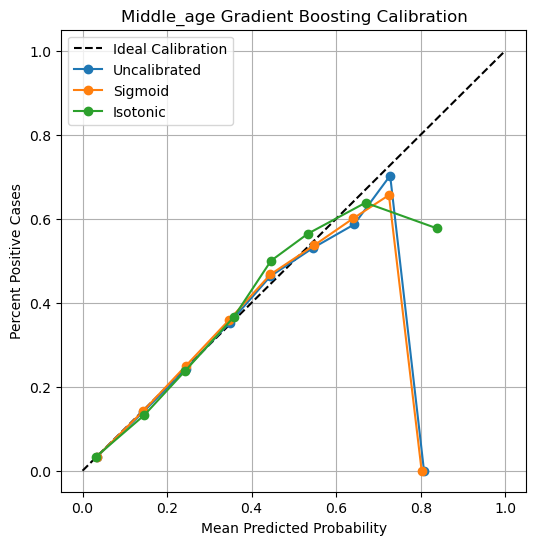

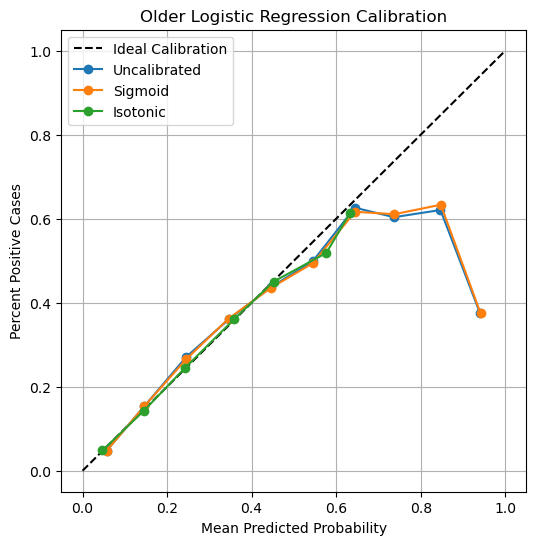

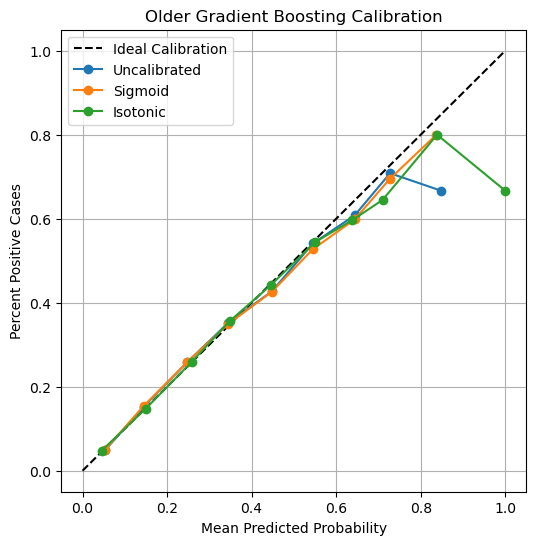

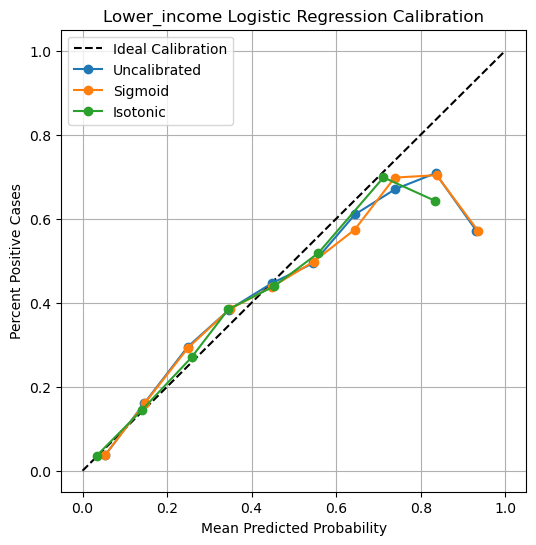

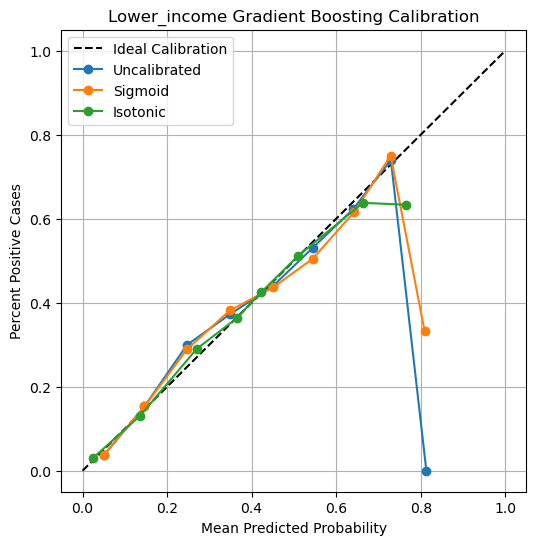

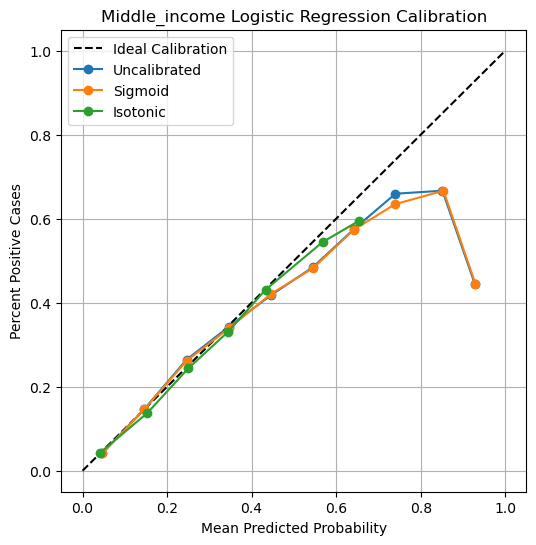

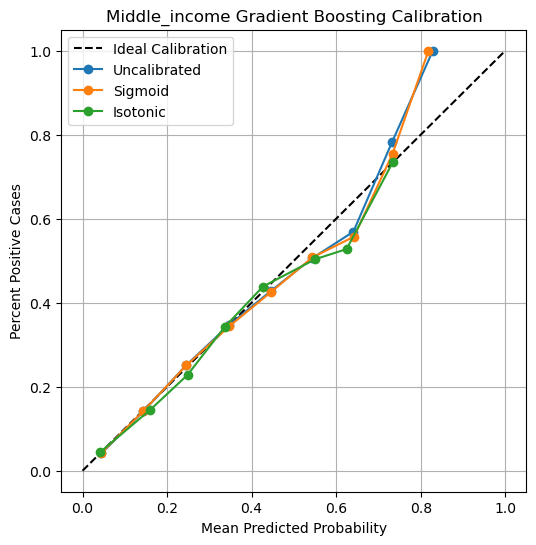

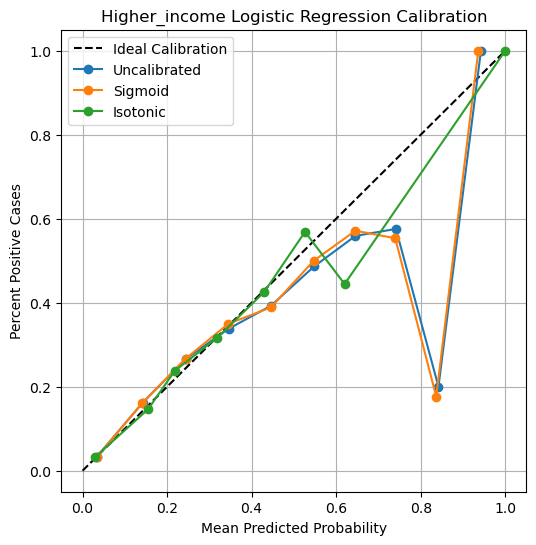

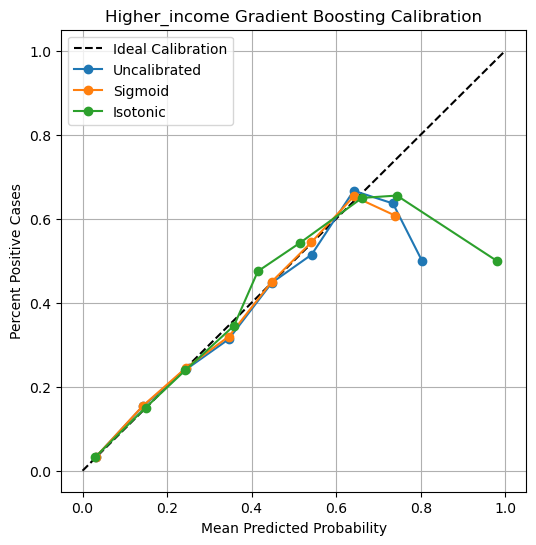

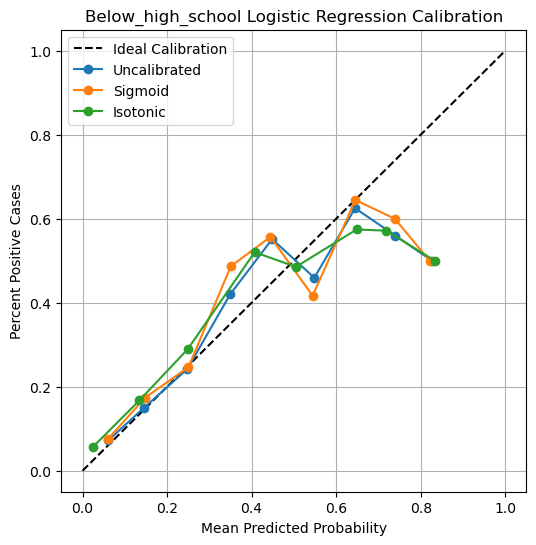

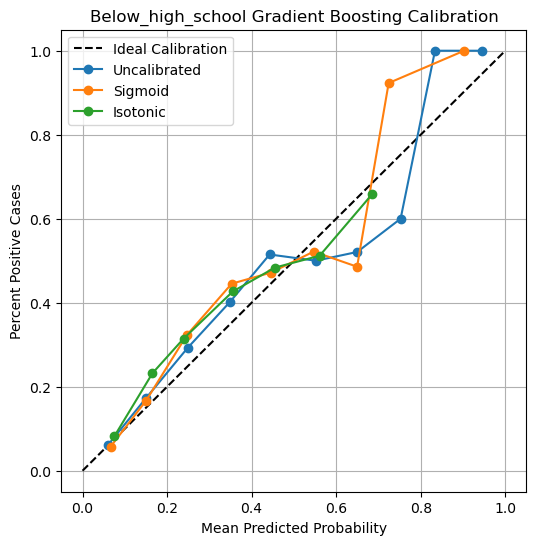

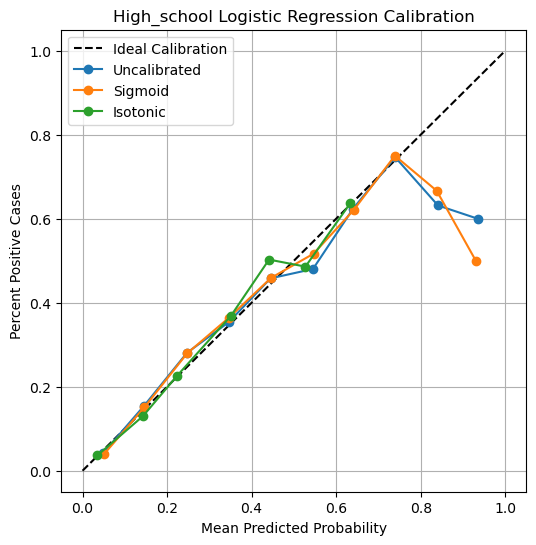

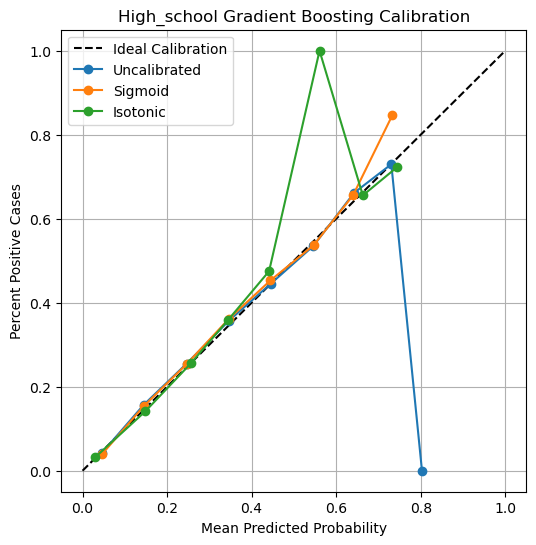

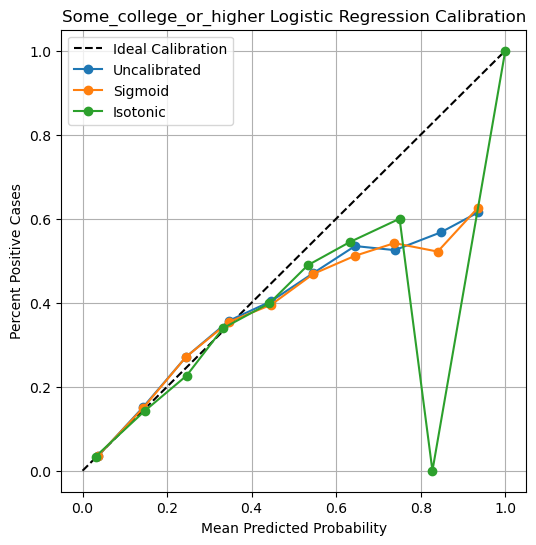

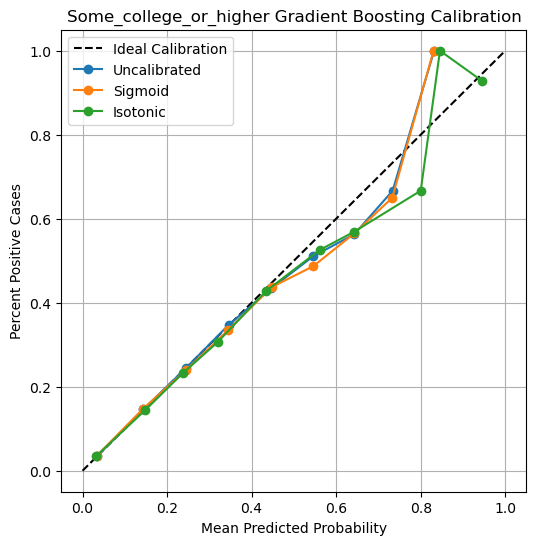

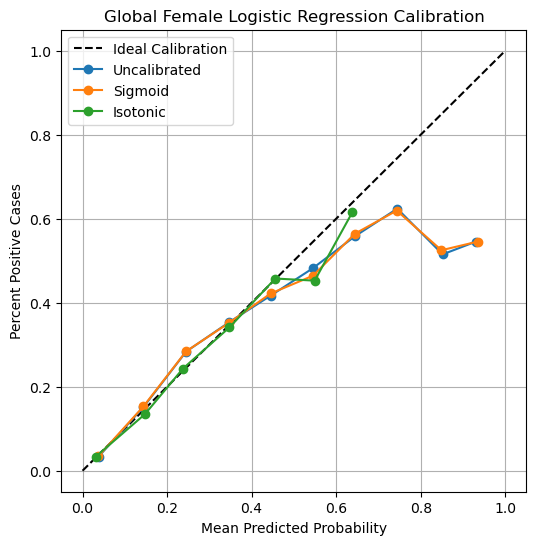

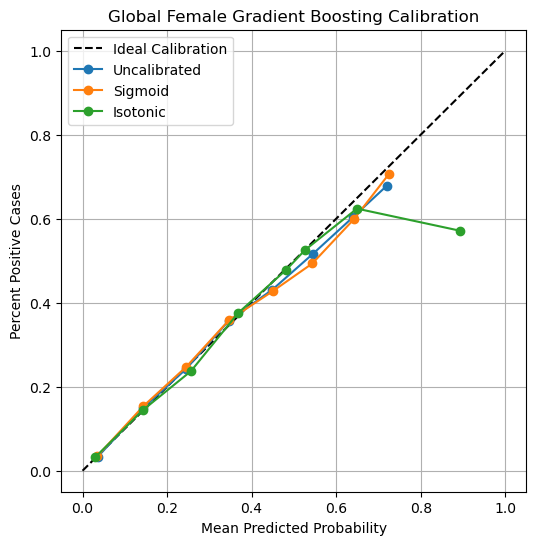

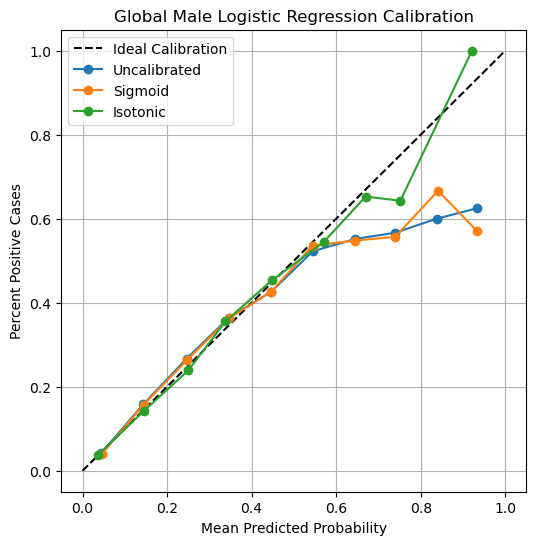

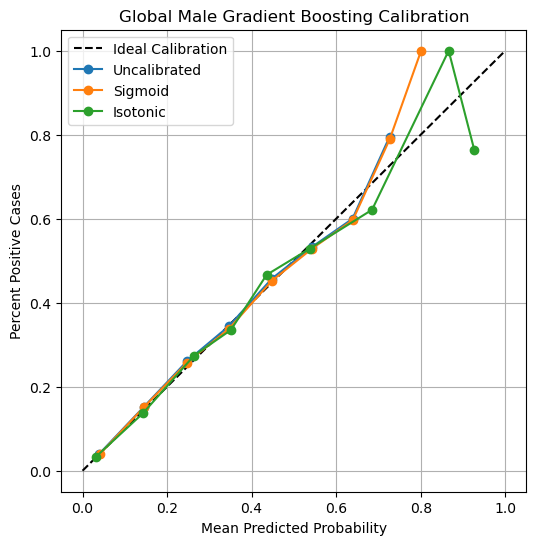

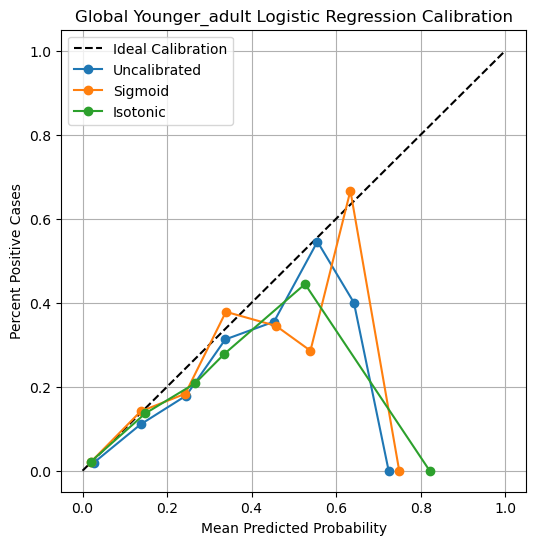

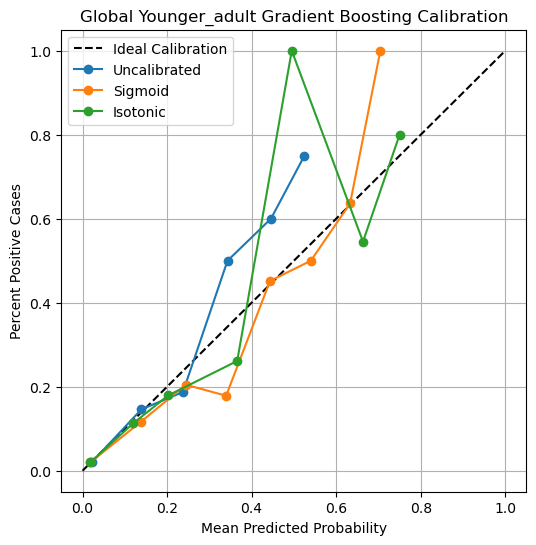

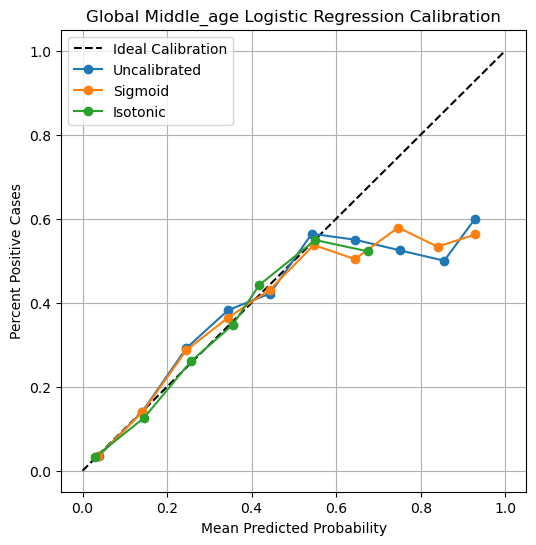

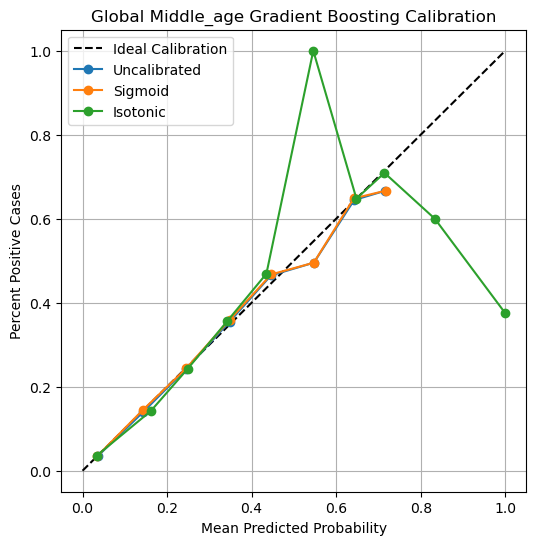

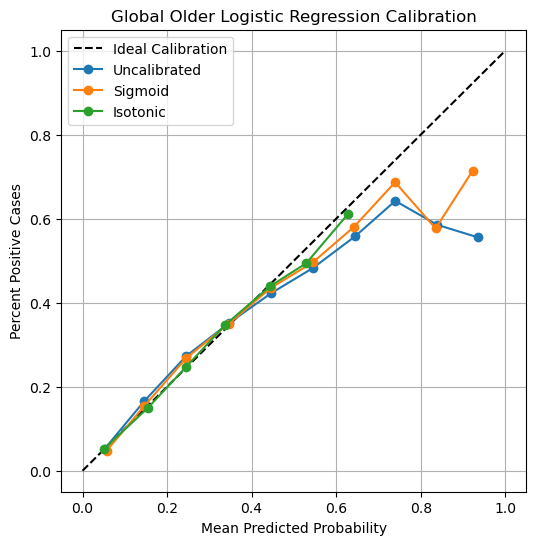

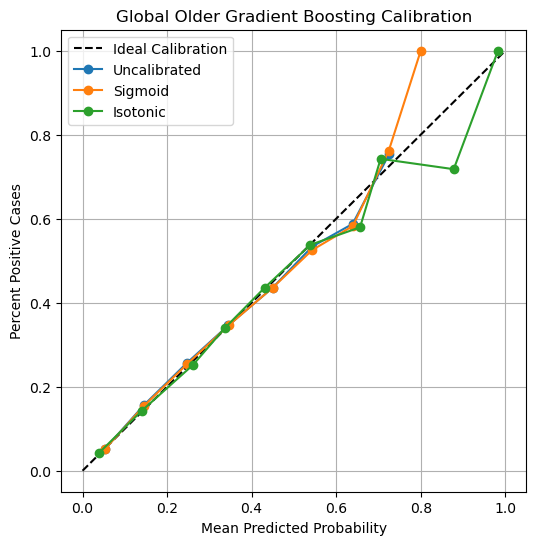

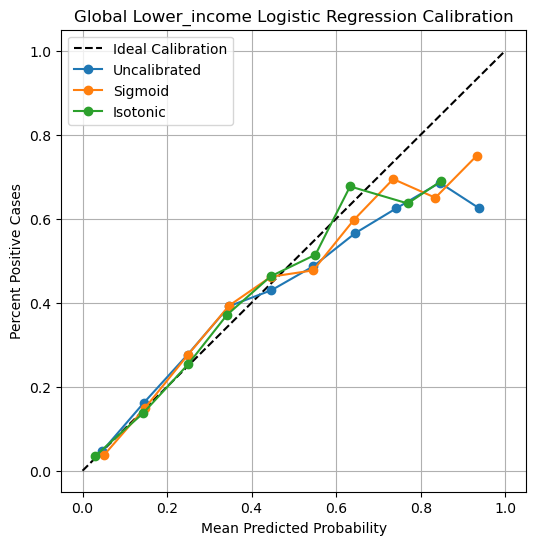

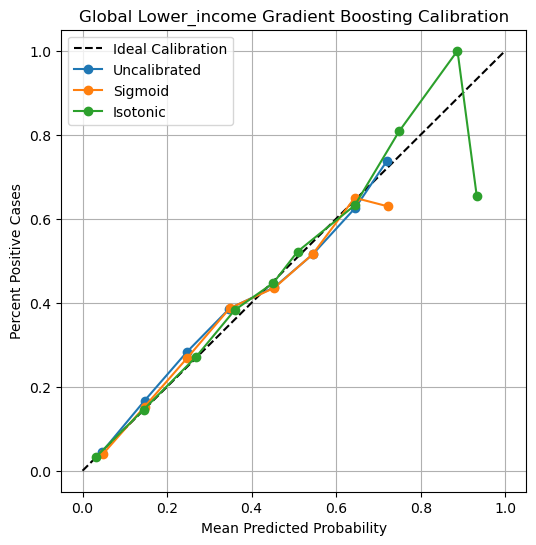

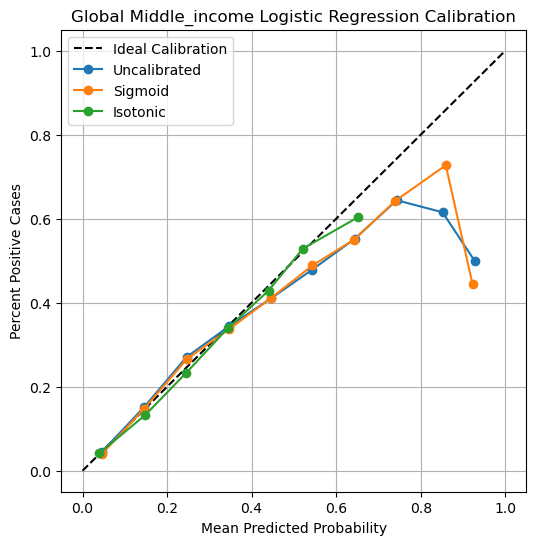

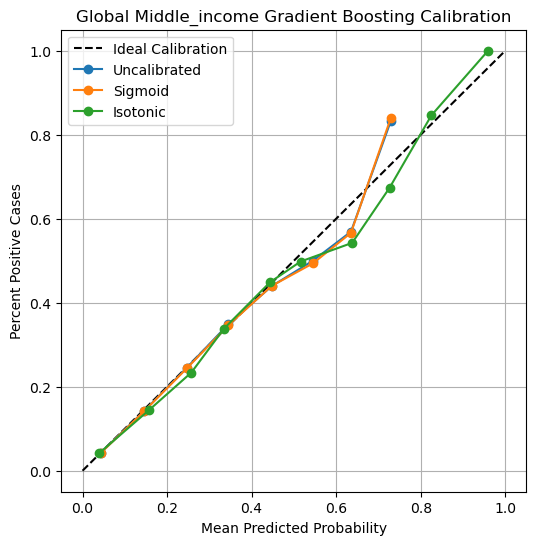

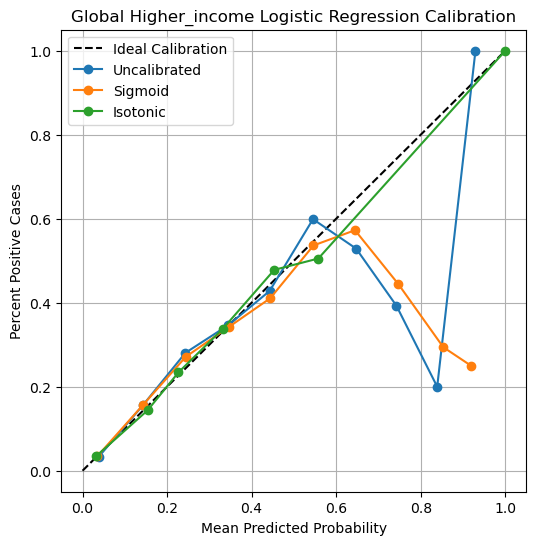

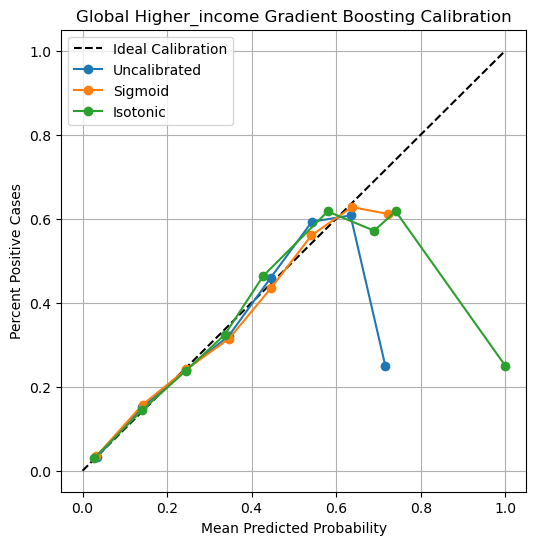

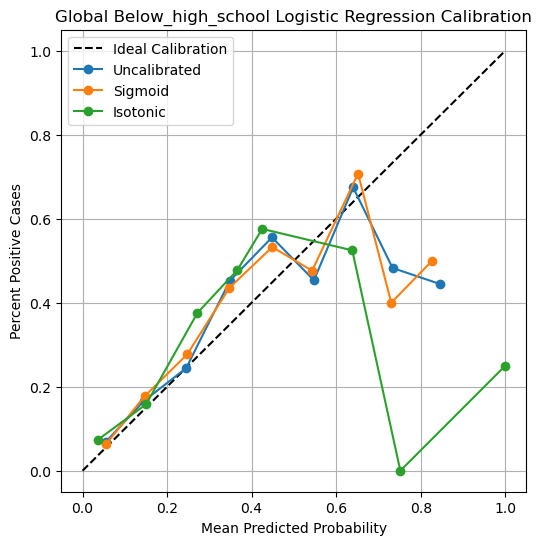

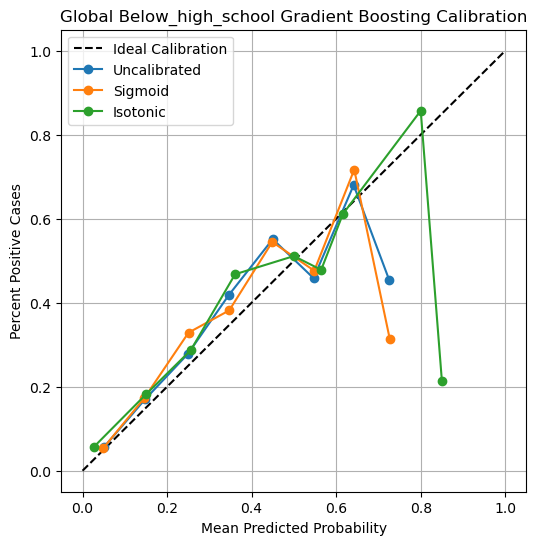

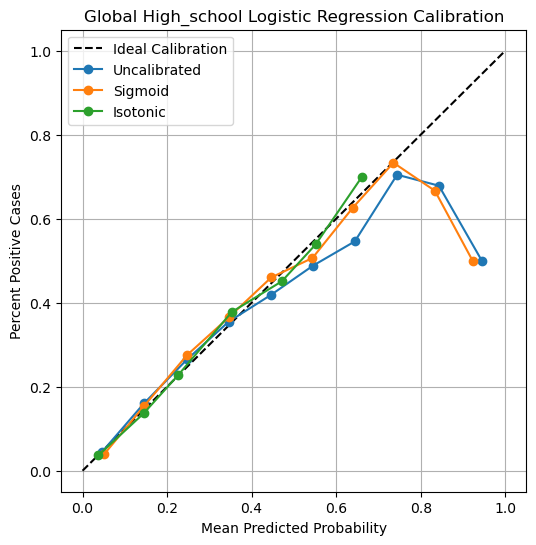

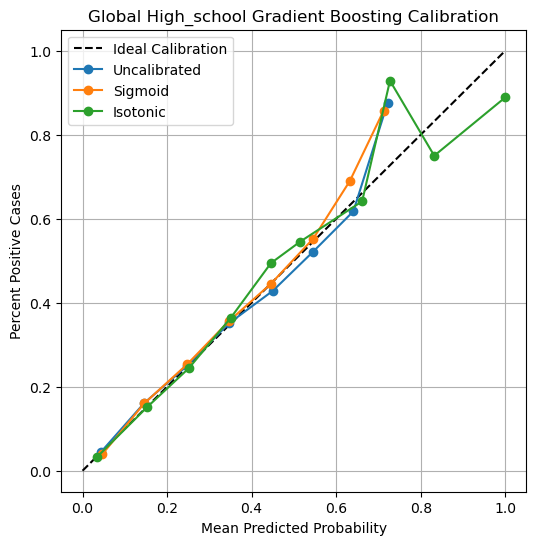

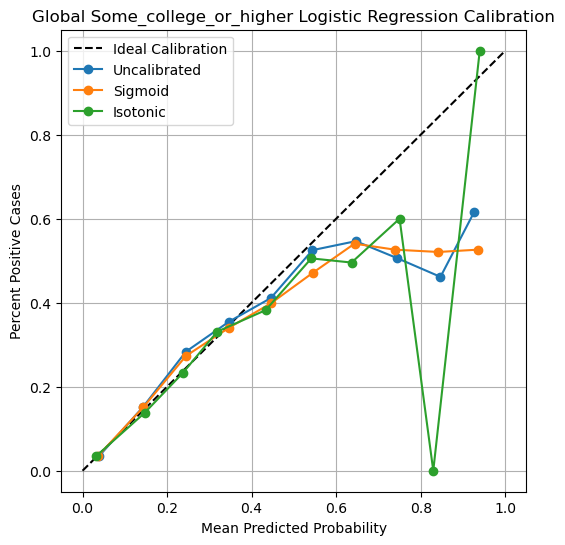

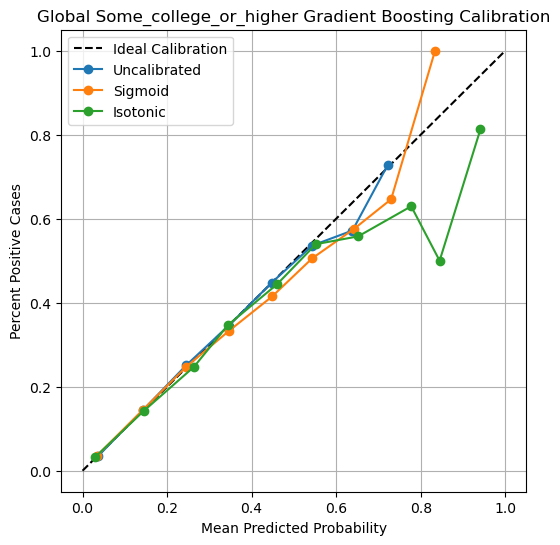

In [8]:
# plot calibration curves for different prediction methods
def plot_calibration_curves(y_true, predictions, title):

    plt.figure(figsize=(6, 6))

    # calbration reference line
    plt.plot([0, 1], [0, 1], "--", color="black", label="Ideal Calibration")

    # plot each model's curve
    for name, y_pred in predictions.items():

        prob_true, prob_pred = calibration_curve(
            y_true,
            y_pred,
            n_bins=10,
            strategy="uniform"
        )

        plt.plot(
            prob_pred,
            prob_true,
            marker="o",
            label=name
        )

    # label and format
    plt.xlabel("Mean Predicted Probability")
    plt.ylabel("Percent Positive Cases")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()


# global Logistic Regression
plot_calibration_curves(
    global_predictions["y_true"],
    {
        "Uncalibrated": global_predictions["log_reg_uncalibrated"],
        "Sigmoid": global_predictions["log_reg_sigmoid"],
        "Isotonic": global_predictions["log_reg_isotonic"]
    },
    "Global Logistic Regression Calibration"
)

# global Gradient Boosting
plot_calibration_curves(
    global_predictions["y_true"],
    {
        "Uncalibrated": global_predictions["gb_uncalibrated"],
        "Sigmoid": global_predictions["gb_sigmoid"],
        "Isotonic": global_predictions["gb_isotonic"]
    },
    "Global Gradient Boosting Calibration"
)

# Demographic Group Calibration Curves
for category, groups in demographic_predictions.items():
    for group, predictions in groups.items():
        plot_calibration_curves(
            predictions["y_true"],
            {
                "Uncalibrated": predictions["log_reg_uncalibrated"],
                "Sigmoid": predictions["log_reg_sigmoid"],
                "Isotonic": predictions["log_reg_isotonic"]
            },
            f"{group.capitalize()} Logistic Regression Calibration"
        )
        plot_calibration_curves(
            predictions["y_true"],
            {
                "Uncalibrated": predictions["gb_uncalibrated"],
                "Sigmoid": predictions["gb_sigmoid"],
                "Isotonic": predictions["gb_isotonic"]
            },
            f"{group.capitalize()} Gradient Boosting Calibration"
        )

# Global Demographic Group Calibration Curves
for category, groups in  global_group_predictions.items():
    for group, predictions in groups.items():
        plot_calibration_curves(
            predictions["y_true"],
            {
                "Uncalibrated": predictions["log_reg_uncalibrated"],
                "Sigmoid": predictions["log_reg_sigmoid"],
                "Isotonic": predictions["log_reg_isotonic"],
            },
            f"Global {group.capitalize()} Logistic Regression Calibration"
        )
        plot_calibration_curves(
            predictions["y_true"],
            {
                "Uncalibrated": predictions["gb_uncalibrated"],
                "Sigmoid": predictions["gb_sigmoid"],
                "Isotonic": predictions["gb_isotonic"]
            },
            f"Global {group.capitalize()} Gradient Boosting Calibration"
        )
    